# Certificación Profesional en Desarrollador de Agentes de IA
## Clase 1 — Demo: RAG de juguete con modelos de Hugging Face

ITBA Educación Ejecutiva

En `clase-01.ipynb` un RAG típico usa **tres piezas**: embeddings (bi-encoder), reranking (cross-encoder) y generación. Este cuaderno las corre sobre un corpus de seis frases, sin base vectorial y sin API key.

Los tres modelos salen de Hugging Face y corren en CPU:

- `sentence-transformers/all-MiniLM-L6-v2` — bi-encoder chico. Embede la consulta y cada chunk **por separado**.
- `cross-encoder/ms-marco-MiniLM-L-6-v2` — lee consulta y chunk **juntos** y devuelve un score.
- `gpt2` — el mismo modelo de la otra demo. Escribe la continuación a partir del contexto que quedó.

La primera ejecución descarga los dos MiniLM (~90 MB cada uno). GPT-2 ya está en el caché si corriste `clase-01-gpt2.ipynb`.


## Qué vamos a ver

1. Un corpus chico y cuántos tokens gasta cada chunk.
2. Recuperación por similitud coseno (bi-encoder).
3. Por qué una frase sobre "temperatura de la sala" compite con la temperatura del softmax, y cómo el cross-encoder separa a ese distractor.
4. Un presupuesto de contexto: no entran todos los chunks recuperados.
5. La misma frase, completada por GPT-2 con evidencia y sin ella.
6. Una consulta cuyo tema no está en el corpus: el top-k igual devuelve algo, y GPT-2 completa igual.


## 1. Corpus

Seis chunks, dos documentos de la guía y dos distractores. El corpus está en inglés porque MiniLM y GPT-2 se entrenaron sobre todo en inglés, y así se puede leer el ranking y la continuación.

No hay chunking automático. Cada frase ya es un chunk: la unidad que se embebe, se reordena y, si entra en el presupuesto, se le pasa al generador.


In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from transformers import (
    AutoModel,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    GPT2LMHeadModel,
    GPT2Tokenizer,
)

corpus = [
    {
        "id": "temp-001",
        "doc": "guia-llms",
        "texto": (
            "Sampling temperature rescales the logits before the softmax. "
            "A low temperature concentrates probability on the most likely next token. "
            "A high temperature flattens the distribution."
        ),
    },
    {
        "id": "bpe-001",
        "doc": "guia-llms",
        "texto": (
            "GPT-2 uses byte-level byte pair encoding. Rare words and text in other "
            "languages split into more tokens, so they consume more of the context window."
        ),
    },
    {
        "id": "emb-001",
        "doc": "guia-rag",
        "texto": (
            "A bi-encoder embeds the query and each document separately. "
            "Similarity is the cosine of the two vectors. Document embeddings can be computed once and stored."
        ),
    },
    {
        "id": "rerank-001",
        "doc": "guia-rag",
        "texto": (
            "A cross-encoder reads the query and one document together and returns a single relevance score. "
            "It is more accurate than cosine similarity, but too slow to run on the whole corpus, "
            "so it only reranks a short candidate list."
        ),
    },
    {
        "id": "clima-001",
        "doc": "distractor",
        "texto": (
            "The room temperature in the server hall should stay near 18 degrees Celsius. "
            "If the room gets hot, the fans spin faster and the machines throttle."
        ),
    },
    {
        "id": "cocina-001",
        "doc": "distractor",
        "texto": (
            "To bake bread, heat the oven to 220 degrees and leave the dough to rise for one hour."
        ),
    },
]

for chunk in corpus:
    print(f"{chunk['id']:<12} {chunk['doc']:<12} {chunk['texto'][:72]}...")


temp-001     guia-llms    Sampling temperature rescales the logits before the softmax. A low tempe...
bpe-001      guia-llms    GPT-2 uses byte-level byte pair encoding. Rare words and text in other l...
emb-001      guia-rag     A bi-encoder embeds the query and each document separately. Similarity i...
rerank-001   guia-rag     A cross-encoder reads the query and one document together and returns a ...
clima-001    distractor   The room temperature in the server hall should stay near 18 degrees Cels...
cocina-001   distractor   To bake bread, heat the oven to 220 degrees and leave the dough to rise ...


## 2. Bi-encoder y similitud coseno

El bi-encoder no lee la consulta y el documento juntos. Cada texto sale como un vector. Si los dos vectores están normalizados, el coseno es el producto punto:

$$\text{sim}(\vec{a}, \vec{b}) = \vec{a} \cdot \vec{b}$$

Los embeddings del corpus se calculan **una vez**. La consulta se embebe recién cuando alguien pregunta. Eso es lo que después vive en un vector store (Clase 5). Acá el corpus tiene 6 vectores, así que buscar es una multiplicación.

El tamaño de cada chunk, en tokens de este mismo tokenizador (WordPiece, no el BPE de un generador):


In [2]:
nombre_bi = "sentence-transformers/all-MiniLM-L6-v2"
tok_bi = AutoTokenizer.from_pretrained(nombre_bi)
enc_bi = AutoModel.from_pretrained(nombre_bi)
enc_bi.eval()


def embeder(textos: list[str]) -> torch.Tensor:
    """Promedio de los tokens, enmascarando el padding, y norma 1."""
    batch = tok_bi(textos, padding=True, truncation=True, return_tensors="pt")
    with torch.no_grad():
        oculto = enc_bi(**batch).last_hidden_state
    mascara = batch["attention_mask"].unsqueeze(-1).float()
    promedio = (oculto * mascara).sum(dim=1) / mascara.sum(dim=1).clamp(min=1e-9)
    return F.normalize(promedio, dim=1)


vectores = embeder([c["texto"] for c in corpus])
print("matriz del corpus:", tuple(vectores.shape), "  (chunks, d)")

print(f"{'id':<12} {'tokens':>7}")
for chunk in corpus:
    chunk["tokens"] = len(tok_bi.encode(chunk["texto"], add_special_tokens=False))
    print(f"{chunk['id']:<12} {chunk['tokens']:7d}")
print("corpus entero:", sum(c["tokens"] for c in corpus), "tokens")


matriz del corpus: (6, 384)   (chunks, d)
id            tokens
temp-001          34
bpe-001           34
emb-001           39
rerank-001        51
clima-001         31
cocina-001        21
corpus entero: 210 tokens


How does temperature change the probability of the next token?
 coseno  id           doc
  0.539  temp-001     guia-llms
  0.354  clima-001    distractor
  0.327  cocina-001   distractor
  0.139  bpe-001      guia-llms


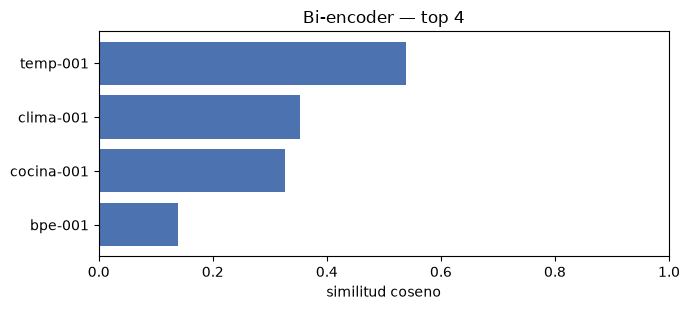

In [3]:
def buscar(consulta: str, k: int = 4) -> list[dict]:
    q = embeder([consulta])
    sims = (vectores @ q.T).squeeze(1)
    orden = torch.argsort(sims, descending=True)[:k]
    return [
        {**corpus[i], "coseno": float(sims[i])}
        for i in orden.tolist()
    ]


def mostrar(consulta: str, hits: list[dict]) -> None:
    print(consulta)
    print(f"{'coseno':>7}  {'id':<12} doc")
    for h in hits:
        print(f"{h['coseno']:7.3f}  {h['id']:<12} {h['doc']}")


consulta_temp = "How does temperature change the probability of the next token?"
hits_temp = buscar(consulta_temp)
mostrar(consulta_temp, hits_temp)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(
    [h["id"] for h in hits_temp][::-1],
    [h["coseno"] for h in hits_temp][::-1],
    color="#4C72B0",
)
ax.set_xlim(0, 1)
ax.set_xlabel("similitud coseno")
ax.set_title("Bi-encoder — top 4")
fig.tight_layout()
plt.show()


`temp-001` habla de la temperatura del softmax. `clima-001` habla de la temperatura de la sala. Comparten la palabra y por eso el coseno de las dos sube: el bi-encoder es rápido, no es un lector. La frase del horno y la de BPE quedan más abajo porque no responden la pregunta.

Otra consulta, para ver que la búsqueda no es solo "la palabra temperature":


In [4]:
consulta_bpe = "Why does a rare word use more of the context window?"
mostrar(consulta_bpe, buscar(consulta_bpe, k=3))


Why does a rare word use more of the context window?
 coseno  id           doc
  0.581  bpe-001      guia-llms
  0.159  rerank-001   guia-rag
  0.136  temp-001     guia-llms


## 3. Cross-encoder: reordenar solo el top-k

El patrón de la clase es: bi-encoder sobre **todo** el corpus, cross-encoder sobre **pocos** candidatos. El segundo modelo no embebe nada. Recibe el par `(consulta, chunk)` y devuelve un logit de relevancia. Más alto es más relevante. No es una probabilidad y no se compara con el coseno: solo ordena a los candidatos entre sí.

En esta consulta el ganador no cambia. Lo que cambia es el margen: `clima-001` queda cerca en el coseno porque comparte la palabra "temperature", y el cross-encoder lo manda al fondo.


In [5]:
nombre_ce = "cross-encoder/ms-marco-MiniLM-L-6-v2"
tok_ce = AutoTokenizer.from_pretrained(nombre_ce)
enc_ce = AutoModelForSequenceClassification.from_pretrained(nombre_ce)
# En algunos builds de PyTorch en CPU, los pesos mapeados desde safetensors
# hacen que la primera capa devuelva NaN. Copiarlos evita ese fallo.
with torch.no_grad():
    for parametro in enc_ce.parameters():
        parametro.data = parametro.data.clone()
enc_ce.eval()


def rerankear(consulta: str, candidatos: list[dict]) -> list[dict]:
    pares = tok_ce(
        [(consulta, c["texto"]) for c in candidatos],
        padding=True,
        truncation=True,
        return_tensors="pt",
    )
    with torch.no_grad():
        logits = enc_ce(**pares).logits.squeeze(-1)
    ordenados = sorted(
        ({**c, "rerank": float(s)} for c, s in zip(candidatos, logits)),
        key=lambda c: c["rerank"],
        reverse=True,
    )
    return ordenados


print("orden del bi-encoder")
for h in hits_temp:
    print(f"  {h['coseno']:7.3f}  {h['id']}")

hits_rerank = rerankear(consulta_temp, hits_temp)
print()
print("después del cross-encoder")
for h in hits_rerank:
    print(f"  {h['rerank']:7.3f}  {h['id']}")


orden del bi-encoder
    0.539  temp-001
    0.354  clima-001
    0.327  cocina-001
    0.139  bpe-001

después del cross-encoder
    5.148  temp-001
  -10.896  clima-001
  -11.048  bpe-001
  -11.164  cocina-001


## 4. Presupuesto de contexto

Recuperar 4 chunks no obliga a pasárselos todos al modelo. Cada uno gasta tokens de una ventana finita. El conteo es el del tokenizador del bi-encoder (un proxy). En un sistema real el tope sale de la ventana del generador menos lo que se reserva para la respuesta. Acá el presupuesto es chico a propósito: entra el primero del ranking y se descarta el resto.


In [6]:
def armar_contexto(chunks: list[dict], max_tokens: int) -> tuple[list[dict], str]:
    usados = []
    gastados = 0
    for chunk in chunks:
        if usados and gastados + chunk["tokens"] > max_tokens:
            break
        usados.append(chunk)
        gastados += chunk["tokens"]
    bloques = [f"[{i}] ({c['doc']}) {c['texto']}" for i, c in enumerate(usados, start=1)]
    return usados, "\n".join(bloques)


presupuesto = 45
usados, contexto = armar_contexto(hits_rerank, presupuesto)
print(f"presupuesto: {presupuesto} tokens")
print("entran:     ", [c["id"] for c in usados], "→", sum(c["tokens"] for c in usados), "tokens")
print("se descartan:", [c["id"] for c in hits_rerank if c not in usados])
print()
print(contexto)


presupuesto: 45 tokens
entran:      ['temp-001'] → 34 tokens
se descartan: ['clima-001', 'bpe-001', 'cocina-001']

[1] (guia-llms) Sampling temperature rescales the logits before the softmax. A low temperature concentrates probability on the most likely next token. A high temperature flattens the distribution.


## 5. Generación con evidencia y sin ella

Las dos primeras piezas eligen y recortan evidencia. Esta es la tercera: escribe texto. GPT-2 no sigue instrucciones: completa. Una pregunta del estilo "Question / Answer" la ignora y sigue de largo. Por eso el prompt es la frase `A low temperature`, una vez sola y otra con el pasaje delante.

Sin el pasaje, la continuación habla de la temperatura del aire. Con el pasaje, copia la frase del chunk que entró en el presupuesto.


In [7]:
modelo = GPT2LMHeadModel.from_pretrained("gpt2")
modelo.eval()
tok_gpt = GPT2Tokenizer.from_pretrained("gpt2", use_fast=True)
if tok_gpt.pad_token is None:
    tok_gpt.pad_token = tok_gpt.eos_token


def completar(prompt: str, max_new_tokens: int = 30) -> str:
    entradas = tok_gpt(prompt, return_tensors="pt")
    with torch.no_grad():
        salida = modelo.generate(
            entradas["input_ids"],
            attention_mask=entradas["attention_mask"],
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tok_gpt.eos_token_id,
        )
    return tok_gpt.decode(salida[0], skip_special_tokens=True)


continuacion = "A low temperature"
sin_evidencia = continuacion
con_evidencia = f"{contexto}\n\n{continuacion}"

print("--- sin corpus ---")
print(completar(sin_evidencia))
print()
print("--- con los chunks que entraron en el presupuesto ---")
print(completar(con_evidencia))
print()
print("tokens del prompt con evidencia:", len(tok_gpt.encode(con_evidencia)))


--- sin corpus ---
A low temperature is a good indicator of the temperature of the air in the room.

The temperature of the air in the room is usually measured in degrees Celsius

--- con los chunks que entraron en el presupuesto ---
[1] (guia-llms) Sampling temperature rescales the logits before the softmax. A low temperature concentrates probability on the most likely next token. A high temperature flattens the distribution.

A low temperature concentrates probability on the most likely next token. A high temperature flattens the distribution. A low temperature concentrates probability on the most likely next token

tokens del prompt con evidencia: 49


## 6. Cuando el corpus no tiene la respuesta

La similitud coseno casi nunca es cero: el top-k devuelve *algo*, aunque ningún chunk hable del tema. GPT-2, además, completa igual. La Torre Eiffel no está en el corpus. La respuesta sale de los pesos, no de la evidencia. Más adelante el curso agrega un umbral de similitud y una instrucción para decir que no alcanza la evidencia. Acá alcanza con ver el hueco.


In [8]:
consulta_vacia = "Where is the Eiffel Tower?"
mostrar(consulta_vacia, buscar(consulta_vacia, k=3))
print()
print(completar("The Eiffel Tower is located in", max_new_tokens=16))


Where is the Eiffel Tower?
 coseno  id           doc
  0.111  clima-001    distractor
  0.019  rerank-001   guia-rag
  0.003  emb-001      guia-rag

The Eiffel Tower is located in the heart of the city, and is the only place in the world where you


## Cierre

- El bi-encoder embebe consulta y chunks por separado. El coseno recupera rápido y se confunde con un vecino léxico (`clima-001`).
- El cross-encoder lee el par junto y abre el margen: el distractor léxico deja de parecer relevante.
- El presupuesto recorta ese ranking. Lo que queda es lo único que ve el generador.
- GPT-2 completa el prompt. Con evidencia se apoya en los chunks; sin evidencia, o con un corpus que no habla del tema, completa igual desde el preentrenamiento.
